# Home Loan Default Risk Management

## Project objectives
1. Prepare a complete data analysis report.
2. Identify factors associated with loan default and customer segments with different risk levels.
3. Compare multiple classification models and recommend a model based on measured performance.
4. Document data challenges, techniques used, and the reasons for choosing them.

**Target:** `TARGET` in `application_train.csv` (`1 = Defaulter`, `0 = Not Defaulter`).


## Import libraries and configure the project

In [1]:
import os
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

PROJECT_PATH = Path(r"data") # Ad  your Dataset Folder Path

FILES = {
    "application_train": "application_train.csv",
    "bureau": "bureau.csv",
    "bureau_balance": "bureau_balance.csv",
    "previous_application": "previous_application.csv",
    "POS_CASH_balance": "POS_CASH_balance.csv",
    "credit_card_balance": "credit_card_balance.csv",
    "installments_payments": "installments_payments.csv",
}

CHUNKSIZE = 200_000
USE_SUPPORTING_DATA = True  # Set False for a first run using application_train only

print("Project folder exists:", PROJECT_PATH.exists())
for name, filename in FILES.items():
    path = PROJECT_PATH / filename
    if path.exists():
        print(f"{filename:30s} {path.stat().st_size / (1024**2):,.1f} MB")
    else:
        print(f"MISSING: {path}")


Project folder exists: True
application_train.csv          158.4 MB
bureau.csv                     162.1 MB
bureau_balance.csv             358.2 MB
previous_application.csv       386.2 MB
POS_CASH_balance.csv           374.5 MB
credit_card_balance.csv        404.9 MB
installments_payments.csv      689.6 MB


## Inspect file schemas without loading full datasets

In [2]:
def inspect_csv(filename, nrows=5):
    path = PROJECT_PATH / filename
    sample = pd.read_csv(path, nrows=nrows)
    print(f"\\n{filename}")
    print("Sample shape:", sample.shape)
    print("Columns:", sample.columns.tolist())
    display(sample.head(3))
    return sample

samples = {}
for name, filename in FILES.items():
    samples[name] = inspect_csv(filename)


\napplication_train.csv
Sample shape: (5, 122)
Columns: ['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPL

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.000","406,597.500","24,700.500","351,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.019,-9461,-637,"-3,648.000",-2120,NaN,1,1,0,1,1,0,Laborers,1.000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083,0.263,0.139,0.025,0.037,0.972,0.619,0.014,0.000,...,0.025,0.037,0.972,0.624,0.014,0.000,0.069,0.083,0.125,0.037,0.021,0.019,0.000,0.000,reg oper account,block of flats,0.015,"Stone, brick",No,2.000,2.000,2.000,2.000,"-1,134.000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,1.000
1,100003,0,Cash loans,F,N,N,0,"270,000.000","1,293,502.500","35,698.500","1,129,500.000",Family,State servant,Higher education,Married,House / apartment,0.004,-16765,-1188,"-1,186.000",-291,NaN,1,1,0,1,1,0,Core staff,2.000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311,0.622,NaN,0.096,0.053,0.985,0.796,0.060,0.080,...,0.097,0.053,0.985,0.799,0.061,0.080,0.035,0.292,0.333,0.013,0.079,0.056,0.004,0.010,reg oper account,block of flats,0.071,Block,No,1.000,0.000,1.000,0.000,-828.000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.000","135,000.000","6,750.000","135,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010,-19046,-225,"-4,260.000",-2531,26.000,1,1,1,1,1,0,Laborers,1.000,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.556,0.730,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,0.000,0.000,-815.000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000


\nbureau.csv
Sample shape: (5, 17)
Columns: ['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.000,-153.000,NaN,0,"91,323.000",0.000,NaN,0.000,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,"1,075.000",NaN,NaN,0,"225,000.000","171,342.000",NaN,0.000,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.000,NaN,NaN,0,"464,323.500",NaN,NaN,0.000,Consumer credit,-16,NaN


\nbureau_balance.csv
Sample shape: (5, 3)
Columns: ['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C


... (4 outputs left out)

\ncredit_card_balance.csv
Sample shape: (5, 23)
Columns: ['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_RECEIVABLE_PRINCIPAL', 'AMT_RECIVABLE', 'AMT_TOTAL_RECEIVABLE', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CNT_DRAWINGS_POS_CURRENT', 'CNT_INSTALMENT_MATURE_CUM', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.000,877.500,0.000,877.500,"1,700.325","1,800.000","1,800.000",0.000,0.000,0.000,0.000,1,0.000,1.000,35.000,Active,0,0
1,2582071,363914,-1,"63,975.555",45000,"2,250.000","2,250.000",0.000,0.000,"2,250.000","2,250.000","2,250.000","60,175.080","64,875.555","64,875.555",1.000,1,0.000,0.000,69.000,Active,0,0
2,1740877,371185,-7,"31,815.225",450000,0.000,0.000,0.000,0.000,"2,250.000","2,250.000","2,250.000","26,926.425","31,460.085","31,460.085",0.000,0,0.000,0.000,30.000,Active,0,0


\ninstallments_payments.csv
Sample shape: (5, 8)
Columns: ['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT']


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.000,6,"-1,180.000","-1,187.000","6,948.360","6,948.360"
1,1330831,151639,0.000,34,"-2,156.000","-2,156.000","1,716.525","1,716.525"
2,2085231,193053,2.000,1,-63.000,-63.000,"25,425.000","25,425.000"


## Load the main application dataset

This is the main modelling table. Each row represents one application in the sample. We retain the original target separately and check that it contains both classes.

In [3]:
main_path = PROJECT_PATH / FILES["application_train"]
data = pd.read_csv(main_path, low_memory=False)

def optimize_dataframe_memory(df):
    """Downcast numeric columns and convert repeated text columns to category."""
    before = df.memory_usage(deep=True).sum() / (1024 ** 2)

    for col in df.select_dtypes(include=["int64"]).columns:
        df[col] = pd.to_numeric(df[col], downcast="integer")

    for col in df.select_dtypes(include=["float64"]).columns:
        df[col] = pd.to_numeric(df[col], downcast="float")

    for col in df.select_dtypes(include=["object"]).columns:
        # Convert only when category encoding is likely to save memory.
        if df[col].nunique(dropna=False) / max(len(df), 1) < 0.50:
            df[col] = df[col].astype("category")

    after = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"Memory: {before:,.1f} MB -> {after:,.1f} MB ({(1-after/before)*100:.1f}% reduction)")
    return df

data = optimize_dataframe_memory(data)

print("Main dataset shape:", data.shape)
display(data.head())


Memory: 325.2 MB -> 96.5 MB (70.3% reduction)
Main dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.000","406,597.500","24,700.500","351,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.019,-9461,-637,"-3,648.000",-2120,NaN,1,1,0,1,1,0,Laborers,1.000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083,0.263,0.139,0.025,0.037,0.972,0.619,0.014,0.000,...,0.025,0.037,0.972,0.624,0.014,0.000,0.069,0.083,0.125,0.038,0.021,0.019,0.000,0.000,reg oper account,block of flats,0.015,"Stone, brick",No,2.000,2.000,2.000,2.000,"-1,134.000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,1.000
1,100003,0,Cash loans,F,N,N,0,"270,000.000","1,293,502.500","35,698.500","1,129,500.000",Family,State servant,Higher education,Married,House / apartment,0.004,-16765,-1188,"-1,186.000",-291,NaN,1,1,0,1,1,0,Core staff,2.000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311,0.622,NaN,0.096,0.053,0.985,0.796,0.060,0.080,...,0.097,0.053,0.985,0.799,0.061,0.080,0.034,0.292,0.333,0.013,0.079,0.056,0.004,0.010,reg oper account,block of flats,0.071,Block,No,1.000,0.000,1.000,0.000,-828.000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.000","135,000.000","6,750.000","135,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010,-19046,-225,"-4,260.000",-2531,26.000,1,1,1,1,1,0,Laborers,1.000,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.556,0.730,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,0.000,0.000,-815.000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000
3,100006,0,Cash loans,F,N,Y,0,"135,000.000","312,682.500","29,686.500","297,000.000",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008,-19005,-3039,"-9,833.000",-2437,NaN,1,1,0,1,0,0,Laborers,2.000,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000,0.000,2.000,0.000,-617.000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


## Initial data quality checks

In [4]:
print("Data types and non-null counts:")
data.info()


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: category(16), float32(64), float64(1), int16(2), int32(2), int8(37)
memory usage: 96.5 MB


In [5]:
display(data.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"307,511.000",NaN,NaN,NaN,"278,180.519","102,790.175","100,002.000","189,145.500","278,202.000","367,142.500","456,255.000"
TARGET,"307,511.000",NaN,NaN,NaN,0.081,0.272,0.000,0.000,0.000,0.000,1.000
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CODE_GENDER,307511,3,F,202448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAG_OWN_CAR,307511,2,N,202924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,"265,992.000",NaN,NaN,NaN,0.007,0.111,0.000,0.000,0.000,0.000,9.000
AMT_REQ_CREDIT_BUREAU_WEEK,"265,992.000",NaN,NaN,NaN,0.034,0.205,0.000,0.000,0.000,0.000,8.000
AMT_REQ_CREDIT_BUREAU_MON,"265,992.000",NaN,NaN,NaN,0.267,0.916,0.000,0.000,0.000,0.000,27.000
AMT_REQ_CREDIT_BUREAU_QRT,"265,992.000",NaN,NaN,NaN,0.265,0.794,0.000,0.000,0.000,0.000,261.000


In [6]:
missing = data.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(data) * 100).round(2)
missing_report = pd.DataFrame({"missing_count": missing, "missing_percent": missing_pct})
display(missing_report.head(40))


,missing_count,missing_percent
COMMONAREA_AVG,214865,69.870
COMMONAREA_MODE,214865,69.870
COMMONAREA_MEDI,214865,69.870
NONLIVINGAPARTMENTS_MEDI,213514,69.430
NONLIVINGAPARTMENTS_MODE,213514,69.430
NONLIVINGAPARTMENTS_AVG,213514,69.430
FONDKAPREMONT_MODE,210295,68.390
LIVINGAPARTMENTS_AVG,210199,68.350
LIVINGAPARTMENTS_MEDI,210199,68.350
LIVINGAPARTMENTS_MODE,210199,68.350


In [7]:
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate application IDs:", data["SK_ID_CURR"].duplicated().sum() if "SK_ID_CURR" in data else "SK_ID_CURR missing")
print("Target values:")
display(data["TARGET"].value_counts(dropna=False))


Duplicate rows: 0
Duplicate application IDs: 0
Target values:


TARGET
0    282686
1     24825
Name: count, dtype: int64

## Target variable analysis

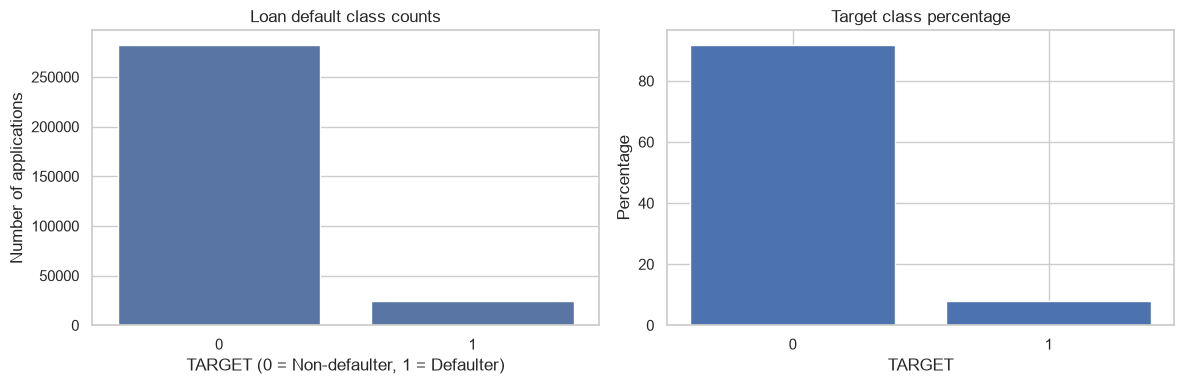

Class percentages:


,percentage
TARGET,
0,91.927
1,8.073


In [8]:
target_counts = data["TARGET"].value_counts().sort_index()
target_pct = data["TARGET"].value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x="TARGET", ax=axes[0])
axes[0].set_title("Loan default class counts")
axes[0].set_xlabel("TARGET (0 = Non-defaulter, 1 = Defaulter)")
axes[0].set_ylabel("Number of applications")

axes[1].bar(target_pct.index.astype(str), target_pct.values)
axes[1].set_title("Target class percentage")
axes[1].set_xlabel("TARGET")
axes[1].set_ylabel("Percentage")
plt.tight_layout()
plt.show()

print("Class percentages:")
display(target_pct.rename("percentage").to_frame())


**Interpretation guide:** In this dataset, defaults are expected to be less common than non-defaults. Confirm the actual imbalance above. Accuracy alone can be misleading when one class dominates, so the model comparison later includes recall, F1, ROC-AUC, and average precision (PR-AUC).

## Univariate and bivariate EDA

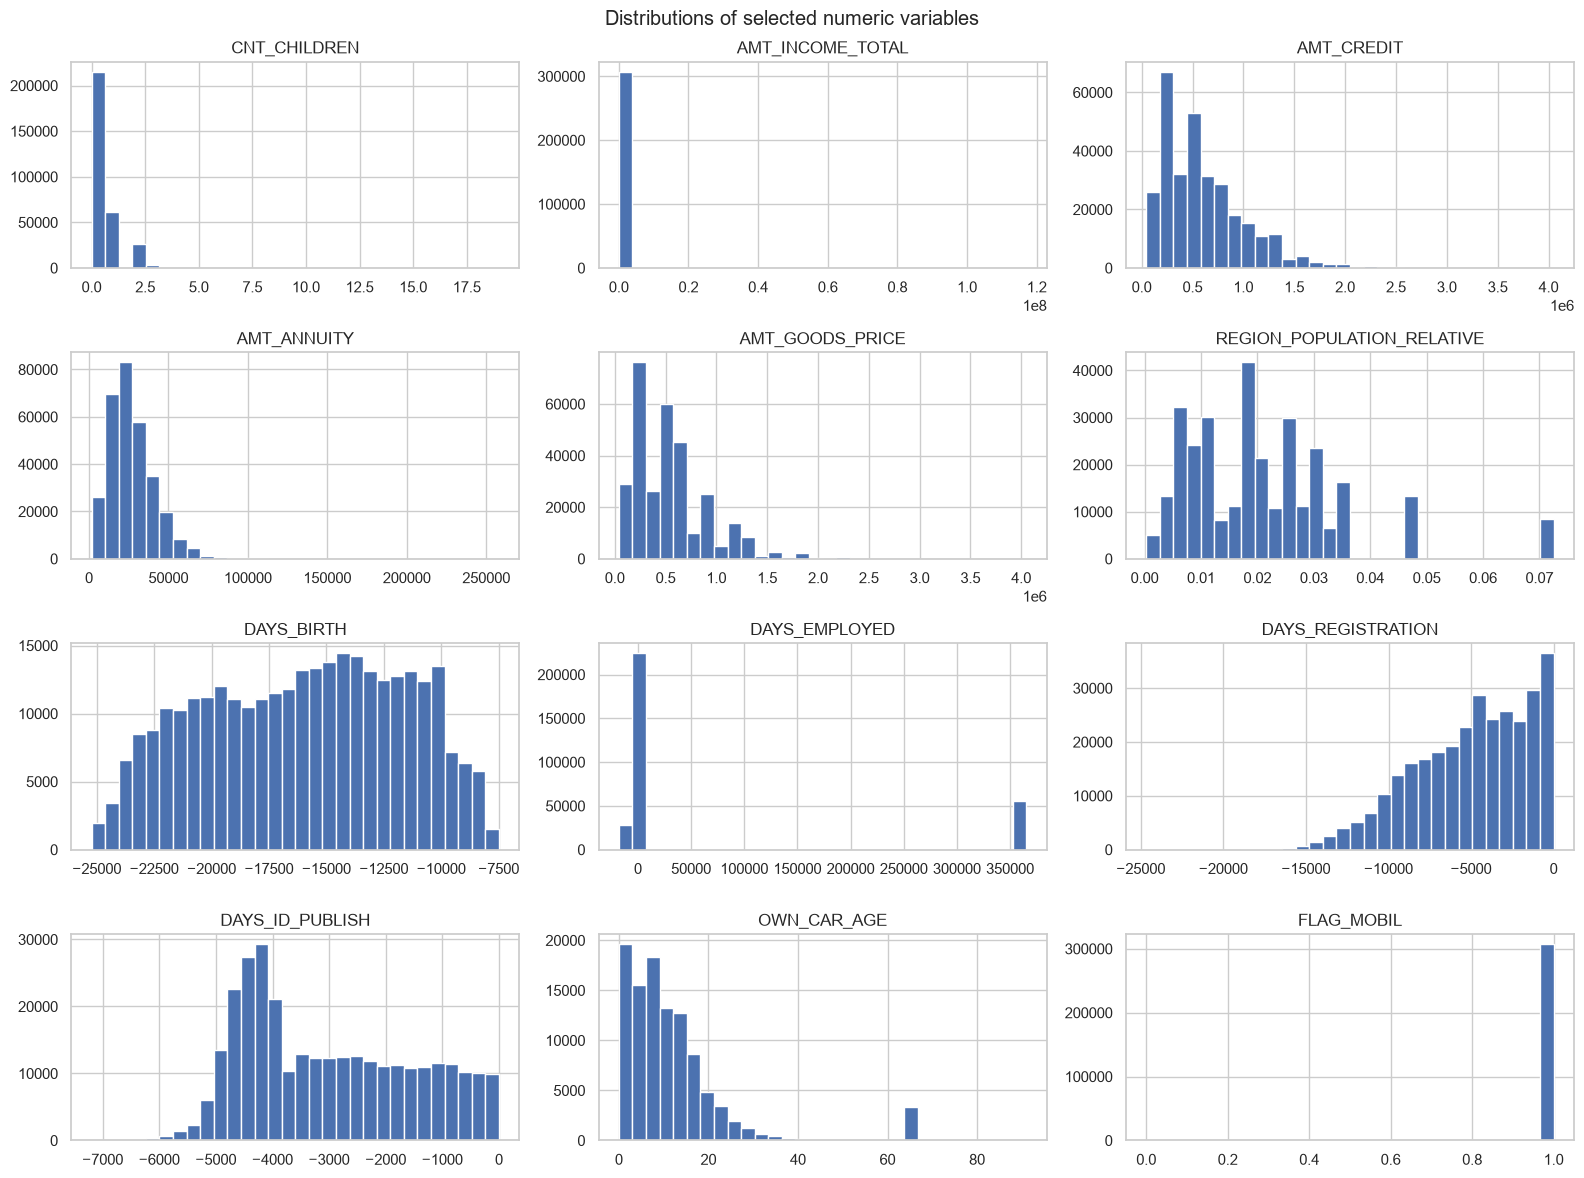

In [9]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ["SK_ID_CURR", "TARGET"]]

# Plot a manageable selection of numeric columns
selected_numeric = numeric_cols[:12]
data[selected_numeric].hist(figsize=(16, 12), bins=30)
plt.suptitle("Distributions of selected numeric variables")
plt.tight_layout()
plt.show()


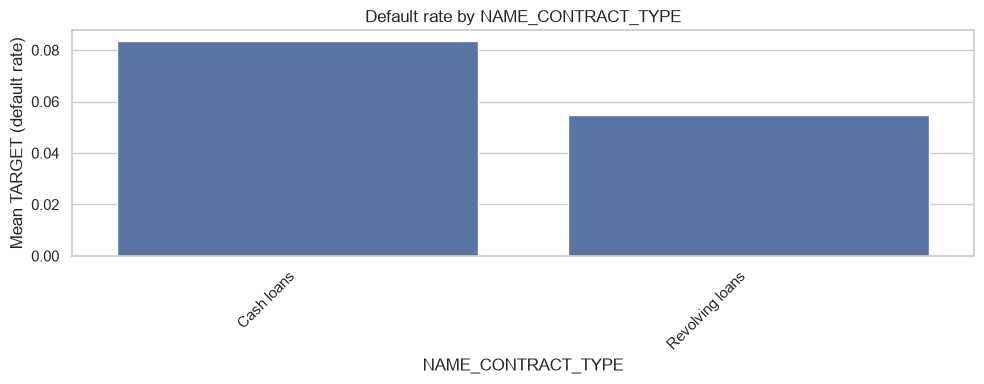

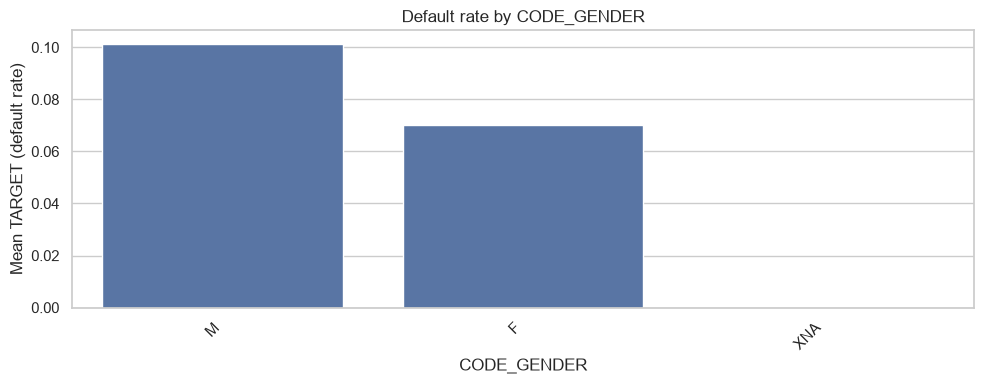

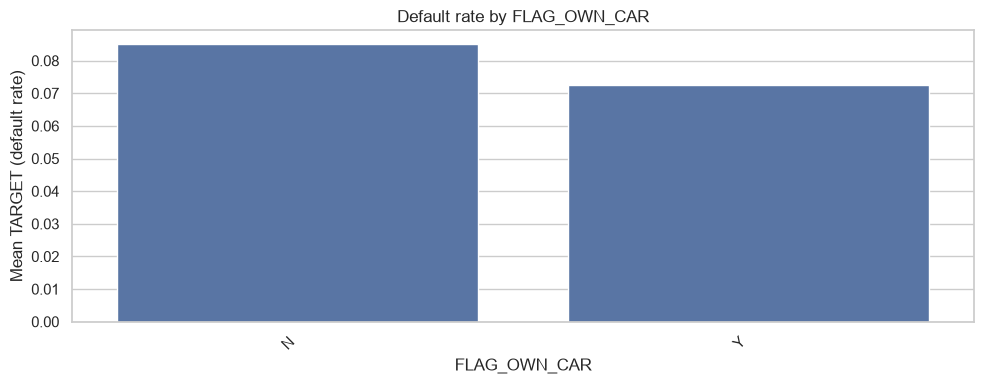

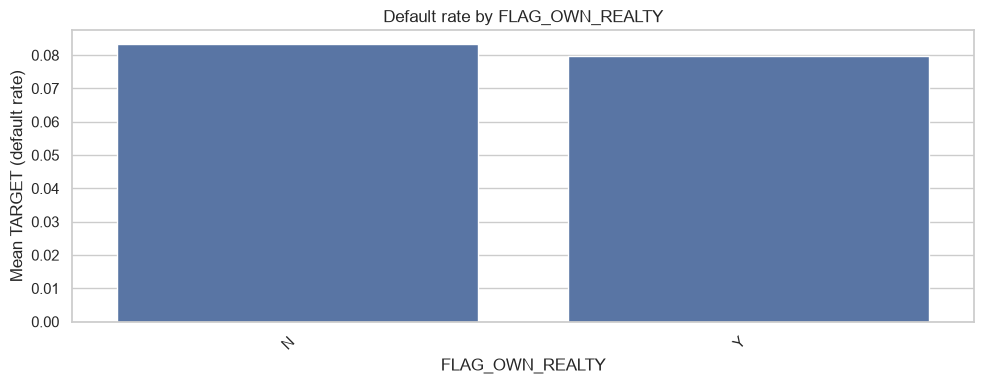

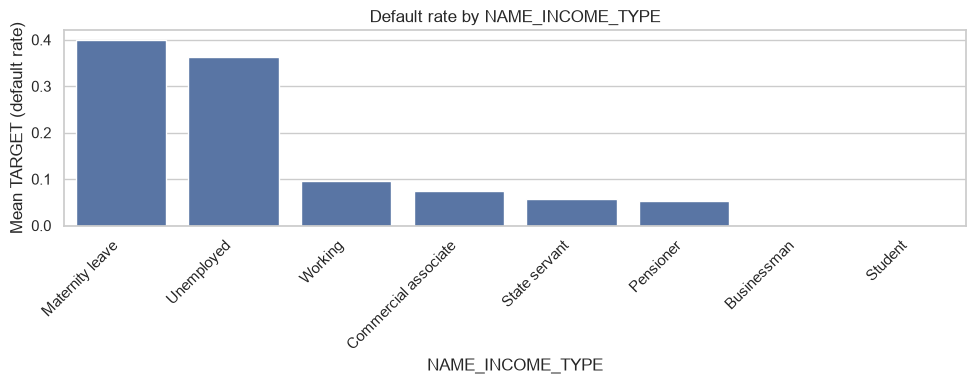

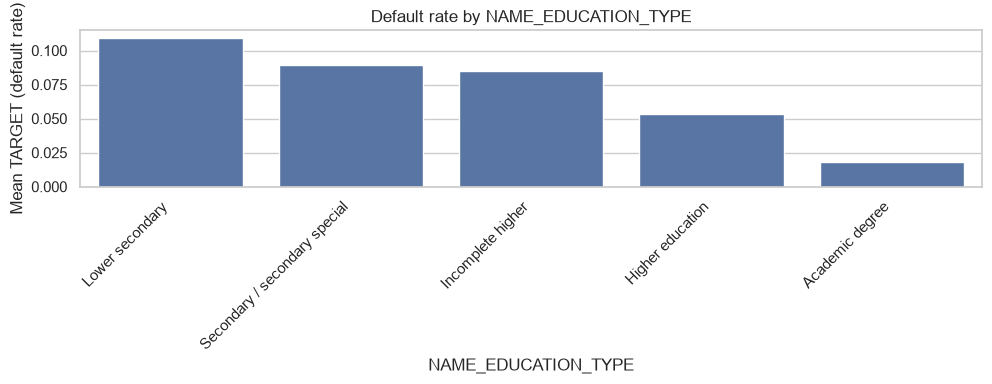

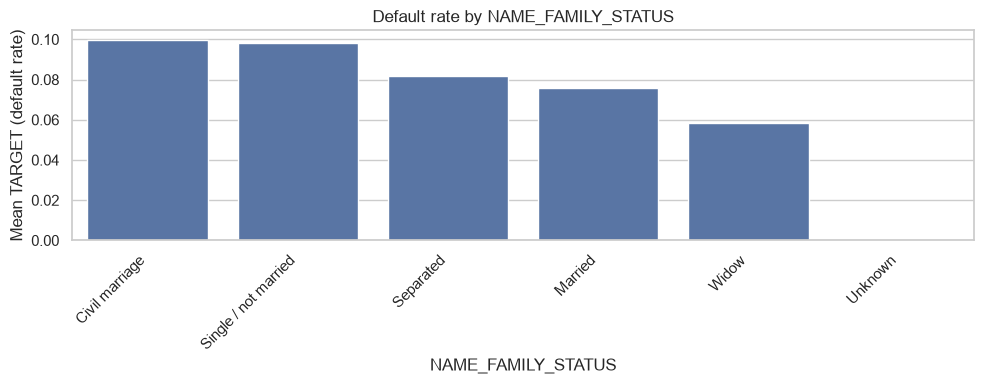

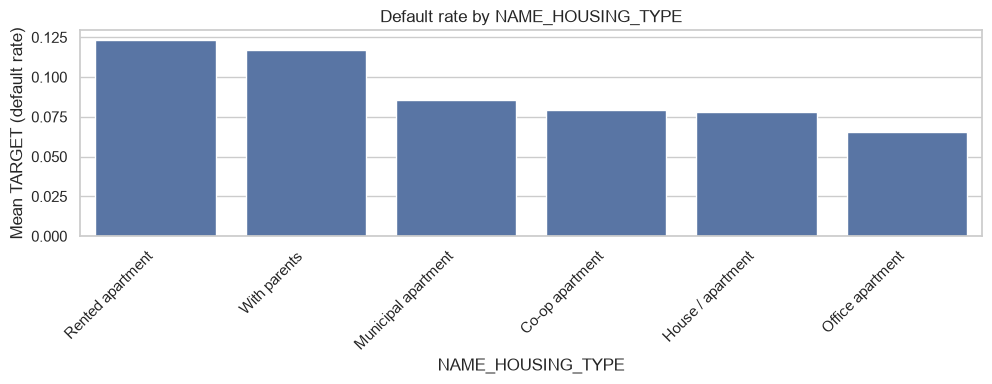

In [10]:
# Default rate by selected categorical variables
candidate_cats = [c for c in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "FLAG_OWN_CAR",
                              "FLAG_OWN_REALTY", "NAME_INCOME_TYPE",
                              "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
                              "NAME_HOUSING_TYPE"] if c in data.columns]

for col in candidate_cats:
    rate = data.groupby(col, dropna=False)["TARGET"].mean().sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=rate.index.astype(str), y=rate.values)
    plt.title(f"Default rate by {col}")
    plt.ylabel("Mean TARGET (default rate)")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


,correlation_with_TARGET
EXT_SOURCE_3,-0.179
EXT_SOURCE_2,-0.160
EXT_SOURCE_1,-0.155
DAYS_BIRTH,0.078
REGION_RATING_CLIENT_W_CITY,0.061
REGION_RATING_CLIENT,0.059
DAYS_LAST_PHONE_CHANGE,0.055
DAYS_ID_PUBLISH,0.051
REG_CITY_NOT_WORK_CITY,0.051
FLAG_EMP_PHONE,0.046


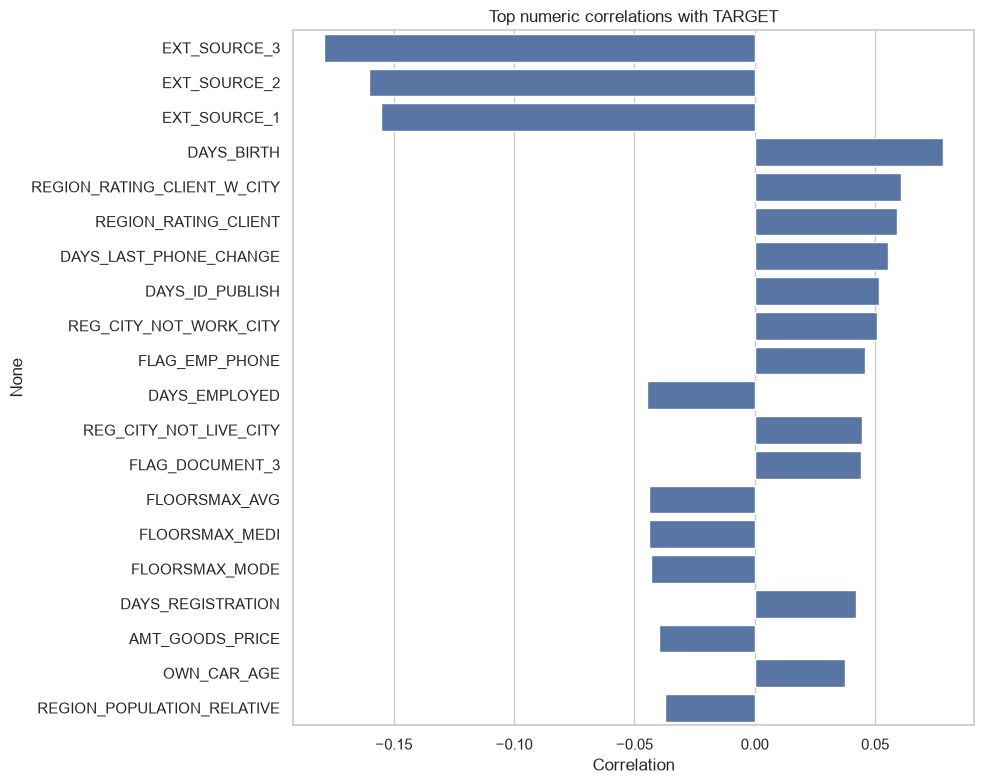

In [11]:
# Correlation with target for numeric variables
corr_target = data[numeric_cols + ["TARGET"]].corr(numeric_only=True)["TARGET"].drop("TARGET")
corr_target = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index)
display(corr_target.head(20).to_frame("correlation_with_TARGET"))

plt.figure(figsize=(10, 8))
sns.barplot(x=corr_target.head(20).values, y=corr_target.head(20).index)
plt.title("Top numeric correlations with TARGET")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()


## Feature engineering on the main application table

In [12]:
# Convert sentinel values used in DAYS_* columns to interpretable years.
# Keep original day columns; add age/tenure-style features where meaningful.
if "DAYS_BIRTH" in data.columns:
    data["AGE_YEARS"] = (-data["DAYS_BIRTH"] / 365.25).round(1)

if "DAYS_EMPLOYED" in data.columns:
    # 365243 is a common sentinel for missing/not-employed in this dataset.
    data["DAYS_EMPLOYED_CLEAN"] = data["DAYS_EMPLOYED"].replace(365243, np.nan)
    data["YEARS_EMPLOYED"] = -data["DAYS_EMPLOYED_CLEAN"] / 365.25
    data["EMPLOYMENT_SENTINEL_FLAG"] = (data["DAYS_EMPLOYED"] == 365243).astype("int8")

if "DAYS_REGISTRATION" in data.columns:
    data["YEARS_REGISTRATION"] = -data["DAYS_REGISTRATION"] / 365.25
if "DAYS_ID_PUBLISH" in data.columns:
    data["YEARS_ID_PUBLISHED"] = -data["DAYS_ID_PUBLISH"] / 365.25

# Ratios can capture affordability; protect against division by zero.
if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(data.columns):
    data["CREDIT_INCOME_RATIO"] = data["AMT_CREDIT"] / data["AMT_INCOME_TOTAL"].replace(0, np.nan)
if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(data.columns):
    data["ANNUITY_INCOME_RATIO"] = data["AMT_ANNUITY"] / data["AMT_INCOME_TOTAL"].replace(0, np.nan)
if {"AMT_GOODS_PRICE", "AMT_CREDIT"}.issubset(data.columns):
    data["GOODS_CREDIT_RATIO"] = data["AMT_GOODS_PRICE"] / data["AMT_CREDIT"].replace(0, np.nan)

display(data.head())


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,AGE_YEARS,DAYS_EMPLOYED_CLEAN,YEARS_EMPLOYED,EMPLOYMENT_SENTINEL_FLAG,YEARS_REGISTRATION,YEARS_ID_PUBLISHED,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,GOODS_CREDIT_RATIO
0,100002,1,Cash loans,M,N,Y,0,"202,500.000","406,597.500","24,700.500","351,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.019,-9461,-637,"-3,648.000",-2120,NaN,1,1,0,1,1,0,Laborers,1.000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083,0.263,0.139,0.025,0.037,0.972,0.619,0.014,0.000,...,0.038,0.021,0.019,0.000,0.000,reg oper account,block of flats,0.015,"Stone, brick",No,2.000,2.000,2.000,2.000,"-1,134.000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,1.000,25.900,-637.000,1.744,0,9.988,5.804,2.008,0.122,0.863
1,100003,0,Cash loans,F,N,N,0,"270,000.000","1,293,502.500","35,698.500","1,129,500.000",Family,State servant,Higher education,Married,House / apartment,0.004,-16765,-1188,"-1,186.000",-291,NaN,1,1,0,1,1,0,Core staff,2.000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311,0.622,NaN,0.096,0.053,0.985,0.796,0.060,0.080,...,0.013,0.079,0.056,0.004,0.010,reg oper account,block of flats,0.071,Block,No,1.000,0.000,1.000,0.000,-828.000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000,45.900,"-1,188.000",3.253,0,3.247,0.797,4.791,0.132,0.873
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.000","135,000.000","6,750.000","135,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010,-19046,-225,"-4,260.000",-2531,26.000,1,1,1,1,1,0,Laborers,1.000,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.556,0.730,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,0.000,0.000,-815.000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000,52.100,-225.000,0.616,0,11.663,6.930,2.000,0.100,1.000
3,100006,0,Cash loans,F,N,Y,0,"135,000.000","312,682.500","29,686.500","297,000.000",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008,-19005,-3039,"-9,833.000",-2437,NaN,1,1,0,1,0,0,Laborers,2.000,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000,0.000,2.000,0.000,-617.000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,5

## Process supporting datasets in chunks

The supporting files contain repeated historical records per customer. We aggregate them to one row per `SK_ID_CURR` before joining to the main application table. The chunk aggregator combines **sums and non-null counts** across chunks, then calculates means; this avoids incorrectly averaging chunk-level averages.

Only numeric columns are aggregated in this general-purpose pass. Categorical history is not silently converted into arbitrary numbers. The number of historical rows is retained as a feature.

In [13]:
def aggregate_numeric_by_customer(filename, prefix, key="SK_ID_CURR", chunksize=CHUNKSIZE):
    """Chunk-read a CSV and calculate per-customer numeric means and row counts."""
    path = PROJECT_PATH / filename
    if not path.exists():
        raise FileNotFoundError(path)

    total_sum = None
    total_count = None
    total_rows = None
    numeric_features = None

    for chunk_no, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False), start=1):
        if key not in chunk.columns:
            raise KeyError(f"{key} not found in {filename}")

        if numeric_features is None:
            numeric_features = [
                c for c in chunk.select_dtypes(include=np.number).columns
                if c not in [key, "SK_ID_BUREAU", "SK_ID_PREV"]
            ]

        grouped = chunk.groupby(key, dropna=True)
        chunk_sum = grouped[numeric_features].sum()
        chunk_count = grouped[numeric_features].count()
        chunk_rows = grouped.size()

        if total_sum is None:
            total_sum, total_count, total_rows = chunk_sum, chunk_count, chunk_rows
        else:
            total_sum = total_sum.add(chunk_sum, fill_value=0)
            total_count = total_count.add(chunk_count, fill_value=0)
            total_rows = total_rows.add(chunk_rows, fill_value=0)

        if chunk_no % 5 == 0:
            print(f"{filename}: processed {chunk_no} chunks")

        del chunk, grouped, chunk_sum, chunk_count, chunk_rows
        gc.collect()

    means = total_sum.div(total_count.replace(0, np.nan))
    means.columns = [f"{prefix}_{c}_MEAN" for c in means.columns]
    result = means
    result[f"{prefix}_RECORD_COUNT"] = total_rows
    result.index.name = key
    return result.reset_index()


In [14]:
support_features = []

if USE_SUPPORTING_DATA:
    # These tables already contain SK_ID_CURR and can be aggregated directly.
    direct_tables = [
        ("bureau.csv", "BUREAU"),
        ("previous_application.csv", "PREV"),
        ("POS_CASH_balance.csv", "POS"),
        ("credit_card_balance.csv", "CC"),
        ("installments_payments.csv", "INST"),
    ]

    for filename, prefix in direct_tables:
        print(f"\\nAggregating {filename} ...")
        agg = aggregate_numeric_by_customer(filename, prefix)
        print("Aggregated shape:", agg.shape)
        support_features.append(agg)
        gc.collect()


\nAggregating bureau.csv ...
bureau.csv: processed 5 chunks
Aggregated shape: (305811, 14)
\nAggregating previous_application.csv ...
previous_application.csv: processed 5 chunks
Aggregated shape: (338857, 21)
\nAggregating POS_CASH_balance.csv ...
POS_CASH_balance.csv: processed 5 chunks
POS_CASH_balance.csv: processed 10 chunks
POS_CASH_balance.csv: processed 15 chunks
POS_CASH_balance.csv: processed 20 chunks
POS_CASH_balance.csv: processed 25 chunks
POS_CASH_balance.csv: processed 30 chunks
POS_CASH_balance.csv: processed 35 chunks
POS_CASH_balance.csv: processed 40 chunks
POS_CASH_balance.csv: processed 45 chunks
POS_CASH_balance.csv: processed 50 chunks
Aggregated shape: (337252, 7)
\nAggregating credit_card_balance.csv ...
credit_card_balance.csv: processed 5 chunks
credit_card_balance.csv: processed 10 chunks
credit_card_balance.csv: processed 15 chunks
credit_card_balance.csv: processed 20 chunks
Aggregated shape: (103558, 22)
\nAggregating installments_payments.csv ...
instal

### Bureau balance aggregation

`bureau_balance.csv` is keyed by `SK_ID_BUREAU`, not directly by `SK_ID_CURR`. First aggregate monthly records by bureau credit ID, then map those credit IDs to the customer IDs in `bureau.csv`. This keeps the relationship between the two tables intact.

In [15]:
if USE_SUPPORTING_DATA:
    bb_path = PROJECT_PATH / FILES["bureau_balance"]
    bb_sum = None
    bb_count = None
    bb_rows = None
    bb_numeric = None

    for chunk_no, chunk in enumerate(pd.read_csv(bb_path, chunksize=CHUNKSIZE, low_memory=False), start=1):
        if bb_numeric is None:
            bb_numeric = [c for c in chunk.select_dtypes(include=np.number).columns
                          if c != "SK_ID_BUREAU"]

        grouped = chunk.groupby("SK_ID_BUREAU", dropna=True)
        part_sum = grouped[bb_numeric].sum()
        part_count = grouped[bb_numeric].count()
        part_rows = grouped.size()

        if bb_sum is None:
            bb_sum, bb_count, bb_rows = part_sum, part_count, part_rows
        else:
            bb_sum = bb_sum.add(part_sum, fill_value=0)
            bb_count = bb_count.add(part_count, fill_value=0)
            bb_rows = bb_rows.add(part_rows, fill_value=0)

        if chunk_no % 5 == 0:
            print(f"bureau_balance.csv: processed {chunk_no} chunks")

        del chunk, grouped, part_sum, part_count, part_rows
        gc.collect()

    bb_credit = bb_sum.div(bb_count.replace(0, np.nan))
    bb_credit["BB_MONTH_RECORD_COUNT"] = bb_rows
    bb_credit = bb_credit.reset_index()

    # Add status frequencies using a separate chunk pass, if STATUS is present.
    if "STATUS" in pd.read_csv(bb_path, nrows=1).columns:
        status_counts = None
        for chunk in pd.read_csv(bb_path, usecols=["SK_ID_BUREAU", "STATUS"],
                                 chunksize=CHUNKSIZE, low_memory=False):
            counts = pd.crosstab(chunk["SK_ID_BUREAU"], chunk["STATUS"])
            if status_counts is None:
                status_counts = counts
            else:
                status_counts = status_counts.add(counts, fill_value=0)
            del chunk, counts
            gc.collect()

        if status_counts is not None:
            status_counts.columns = [f"BB_STATUS_{str(c)}_COUNT" for c in status_counts.columns]
            bb_credit = bb_credit.merge(status_counts.reset_index(), on="SK_ID_BUREAU", how="left")

    bureau_keys = pd.read_csv(PROJECT_PATH / FILES["bureau"],
                              usecols=["SK_ID_BUREAU", "SK_ID_CURR"])
    bb_customer = bb_credit.merge(bureau_keys, on="SK_ID_BUREAU", how="left")

    # Aggregate credit-level monthly summaries to customer level.
    bb_value_cols = [c for c in bb_customer.select_dtypes(include=np.number).columns
                     if c not in ["SK_ID_BUREAU", "SK_ID_CURR"]]
    bb_customer_agg = bb_customer.groupby("SK_ID_CURR")[bb_value_cols].mean()
    bb_customer_agg.columns = [f"BB_{c}_MEAN" for c in bb_customer_agg.columns]
    bb_customer_agg["BB_CREDIT_COUNT"] = bb_customer.groupby("SK_ID_CURR")["SK_ID_BUREAU"].nunique()
    bb_customer_agg = bb_customer_agg.reset_index()

    support_features.append(bb_customer_agg)
    print("Bureau balance customer features:", bb_customer_agg.shape)

    del bb_credit, bb_customer, bb_customer_agg, bureau_keys, bb_sum, bb_count, bb_rows
    gc.collect()


bureau_balance.csv: processed 5 chunks
bureau_balance.csv: processed 10 chunks
bureau_balance.csv: processed 15 chunks
bureau_balance.csv: processed 20 chunks
bureau_balance.csv: processed 25 chunks
bureau_balance.csv: processed 30 chunks
bureau_balance.csv: processed 35 chunks
bureau_balance.csv: processed 40 chunks
bureau_balance.csv: processed 45 chunks
bureau_balance.csv: processed 50 chunks
bureau_balance.csv: processed 55 chunks
bureau_balance.csv: processed 60 chunks
bureau_balance.csv: processed 65 chunks
bureau_balance.csv: processed 70 chunks
bureau_balance.csv: processed 75 chunks
bureau_balance.csv: processed 80 chunks
bureau_balance.csv: processed 85 chunks
bureau_balance.csv: processed 90 chunks
bureau_balance.csv: processed 95 chunks
bureau_balance.csv: processed 100 chunks
bureau_balance.csv: processed 105 chunks
bureau_balance.csv: processed 110 chunks
bureau_balance.csv: processed 115 chunks
bureau_balance.csv: processed 120 chunks
bureau_balance.csv: processed 125 ch

## Merge customer-level historical features

In [16]:
model_data = data.copy()

for feature_table in support_features:
    model_data = model_data.merge(feature_table, on="SK_ID_CURR", how="left", validate="one_to_one")

print("Merged modelling dataset shape:", model_data.shape)
print("Duplicate customer IDs after merge:", model_data["SK_ID_CURR"].duplicated().sum())
display(model_data.head())


Merged modelling dataset shape: (307511, 209)
Duplicate customer IDs after merge: 0


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,PREV_DAYS_LAST_DUE_1ST_VERSION_MEAN,PREV_DAYS_LAST_DUE_MEAN,PREV_DAYS_TERMINATION_MEAN,PREV_NFLAG_INSURED_ON_APPROVAL_MEAN,PREV_RECORD_COUNT,POS_MONTHS_BALANCE_MEAN,POS_CNT_INSTALMENT_MEAN,POS_CNT_INSTALMENT_FUTURE_MEAN,POS_SK_DPD_MEAN,POS_SK_DPD_DEF_MEAN,POS_RECORD_COUNT,CC_MONTHS_BALANCE_MEAN,CC_AMT_BALANCE_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_INST_MIN_REGULARITY_MEAN,CC_AMT_PAYMENT_CURRENT_MEAN,CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,CC_AMT_RECIVABLE_MEAN,CC_AMT_TOTAL_RECEIVABLE_MEAN,CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,CC_CNT_DRAWINGS_CURRENT_MEAN,CC_CNT_DRAWINGS_OTHER_CURRENT_MEAN,CC_CNT_DRAWINGS_POS_CURRENT_MEAN,CC_CNT_INSTALMENT_MATURE_CUM_MEAN,CC_SK_DPD_MEAN,CC_SK_DPD_DEF_MEAN,CC_RECORD_COUNT,INST_NUM_INSTALMENT_VERSION_MEAN,INST_NUM_INSTALMENT_NUMBER_MEAN,INST_DAYS_INSTALMENT_MEAN,INST_DAYS_ENTRY_PAYMENT_MEAN,INST_AMT_INSTALMENT_MEAN,INST_AMT_PAYMENT_MEAN,INST_RECORD_COUNT,BB_MONTHS_BALANCE_MEAN,BB_BB_MONTH_RECORD_COUNT_MEAN,BB_BB_STATUS_0_COUNT_MEAN,BB_BB_STATUS_1_COUNT_MEAN,BB_BB_STATUS_2_COUNT_MEAN,BB_BB_STATUS_3_COUNT_MEAN,BB_BB_STATUS_4_COUNT_MEAN,BB_BB_STATUS_5_COUNT_MEAN,BB_BB_STATUS_C_COUNT_MEAN,BB_BB_STATUS_X_COUNT_MEAN,BB_CREDIT_COUNT
0,100002,1,Cash loans,M,N,Y,0,"202,500.000","406,597.500","24,700.500","351,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.019,-9461,-637,"-3,648.000",-2120,NaN,1,1,0,1,1,0,Laborers,1.000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083,0.263,0.139,0.025,0.037,0.972,0.619,0.014,0.000,...,125.000,-25.000,-17.000,0.000,1.000,-10.000,24.000,15.000,0.000,0.000,19.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.053,10.000,-295.000,-315.421,"11,559.247","11,559.247",19.000,-21.875,13.750,5.625,3.375,0.000,0.000,0.000,0.000,2.875,1.875,8.000
1,100003,0,Cash loans,F,N,N,0,"270,000.000","1,293,502.500","35,698.500","1,129,500.000",Family,State servant,Higher education,Married,House / apartment,0.004,-16765,-1188,"-1,186.000",-291,NaN,1,1,0,1,1,0,Core staff,2.000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311,0.622,NaN,0.096,0.053,0.985,0.796,0.060,0.080,...,"-1,004.333","-1,054.333","-1,047.333",0.667,3.000,-43.786,10.107,5.786,0.000,0.000,28.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.040,5.080,"-1,378.160","-1,385.320","64,754.586","64,754.586",25.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.000","135,000.000","6,750.000","135,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010,-19046,-225,"-4,260.000",-2531,26.000,1,1,1,1,1,0,Laborers,1.000,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.556,0.730,NaN,NaN,NaN,NaN,NaN,NaN,...,-694.000,-724.000,-714.000,0.000,1.000,-25.500,3.750,2.250,0.000,0.000,4.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.333,2.000,-754.000,-761.667,"7,096.155","7,096.155",3.000,N

**Note:** A left join preserves every application in the main training table. Missing historical aggregates mean no matching historical record or no observed value; they are handled by the modelling pipeline. We do not use `SK_ID_CURR` as a predictive feature.

## Prepare features and target

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

TARGET = "TARGET"
DROP_COLS = [TARGET, "SK_ID_CURR"]

X = model_data.drop(columns=[c for c in DROP_COLS if c in model_data.columns])
y = model_data[TARGET].astype("int8")

# Remove columns that are completely empty and columns with a single value.
X = X.dropna(axis=1, how="all")
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_cols)

# Optional reproducible sample for faster local experimentation.
# Set SAMPLE_SIZE = None to use all rows if your computer has sufficient RAM.
SAMPLE_SIZE = 100_000
if SAMPLE_SIZE is not None and len(X) > SAMPLE_SIZE:
    X, _, y, _ = train_test_split(
        X, y, train_size=SAMPLE_SIZE, random_state=42, stratify=y
    )

print("Rows used:", len(X))
print("Features:", X.shape[1])
print("Target distribution:")
display(y.value_counts(normalize=True).rename("proportion").to_frame())

from sklearn.base import clone
from sklearn.metrics import fbeta_score


Rows used: 100000
Features: 207
Target distribution:


,proportion
TARGET,
0,0.919
1,0.081


In [18]:
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=True)
except TypeError:  # scikit-learn versions before 1.2
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse=True)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop",
    sparse_threshold=1.0
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Training shape: (80000, 207)
Testing shape: (20000, 207)
Numeric features: 191
Categorical features: 16


## Train and compare classification models

We compare a majority-class baseline, Logistic Regression, Random Forest, and Extra Trees. Class weighting is used for the classifiers that support it because the target may be imbalanced. All preprocessing is inside each pipeline, so imputers, scaling, and category encoding are fitted on training data only.

In [19]:
from sklearn.tree import DecisionTreeClassifier

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1200, class_weight="balanced", solver="saga", n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=30, class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=18, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150, max_depth=18, min_samples_leaf=5,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
}

# Add gradient-boosting libraries only when installed in this Jupyter environment.
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=250, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="binary:logistic", eval_metric="aucpr",
        tree_method="hist", n_jobs=-1, random_state=42
    )
    print("XGBoost is available.")
except ImportError:
    print("XGBoost not installed; skipping it. Install with: %pip install xgboost")

try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        n_estimators=300, learning_rate=0.04, num_leaves=31,
        class_weight="balanced", subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbosity=-1
    )
    print("LightGBM is available.")
except ImportError:
    print("LightGBM not installed; skipping it. Install with: %pip install lightgbm")

results = []
fitted_models = {}

for name, estimator in models.items():
    print(f"Training {name} ...")
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob) if prob is not None else np.nan,
        "PR_AUC": average_precision_score(y_test, prob) if prob is not None else np.nan
    })
    fitted_models[name] = pipe
    print("Completed:", name)

    del pred, prob
    gc.collect()

comparison = pd.DataFrame(results).sort_values("PR_AUC", ascending=False)
display(comparison)


XGBoost not installed; skipping it. Install with: %pip install xgboost
LightGBM not installed; skipping it. Install with: %pip install lightgbm
Training Dummy Baseline ...
Completed: Dummy Baseline
Training Logistic Regression ...
Completed: Logistic Regression
Training Decision Tree ...
Completed: Decision Tree
Training Random Forest ...
Completed: Random Forest
Training Extra Trees ...
Completed: Extra Trees


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,Logistic Regression,0.703,0.168,0.677,0.269,0.757,0.231
3,Random Forest,0.897,0.272,0.166,0.206,0.738,0.204
4,Extra Trees,0.822,0.202,0.409,0.271,0.721,0.200
2,Decision Tree,0.647,0.132,0.602,0.216,0.664,0.162
0,Dummy Baseline,0.919,0.000,0.000,0.000,0.500,0.081


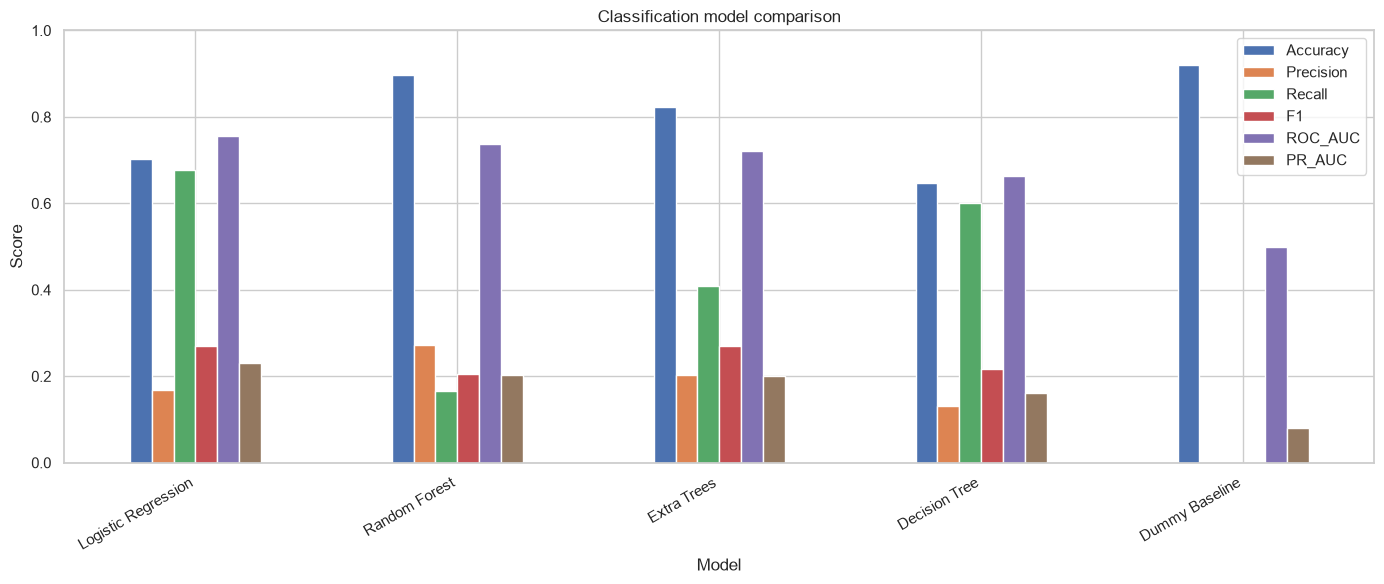

In [20]:
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]].plot(
    kind="bar", figsize=(14, 6)
)
plt.title("Classification model comparison")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## Evaluate the selected model

Selected model based on PR-AUC: Logistic Regression
                   precision    recall  f1-score   support

Non-defaulter (0)       0.96      0.71      0.81     18385
    Defaulter (1)       0.17      0.68      0.27      1615

         accuracy                           0.70     20000
        macro avg       0.56      0.69      0.54     20000
     weighted avg       0.90      0.70      0.77     20000



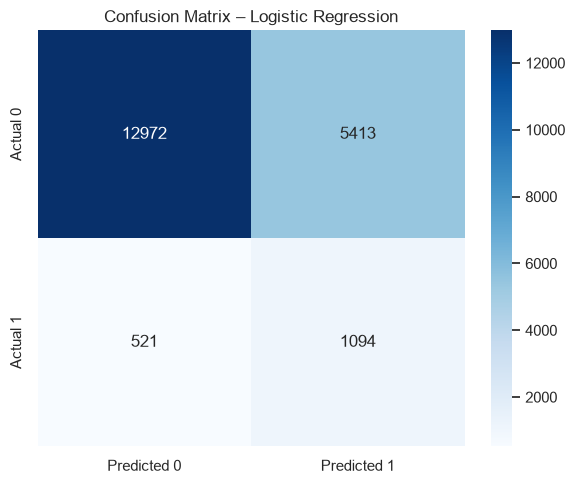

In [21]:
# Select the model with the highest PR-AUC; this is often useful for an imbalanced default target.
best_model_name = comparison.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Selected model based on PR-AUC:", best_model_name)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, y_pred,
    target_names=["Non-defaulter (0)", "Defaulter (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title(f"Confusion Matrix – {best_model_name}")
plt.tight_layout()
plt.show()


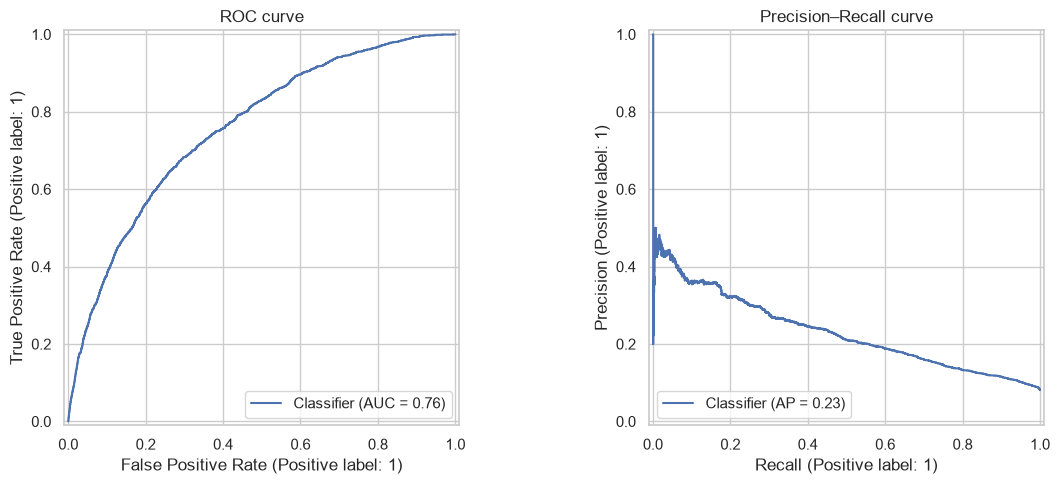

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[0])
axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title("Precision–Recall curve")
plt.tight_layout()
plt.show()


## Model comparison report

In [23]:
best_row = comparison.iloc[0]
print("MODEL COMPARISON REPORT")
print("----------------------")
print(comparison.to_string(index=False))
print(f"\\nRecommended candidate based on PR-AUC: {best_row['Model']}")
print(f"PR-AUC: {best_row['PR_AUC']:.4f}")
print(f"ROC-AUC: {best_row['ROC_AUC']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"F1: {best_row['F1']:.4f}")


MODEL COMPARISON REPORT
----------------------
              Model  Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC
Logistic Regression     0.703      0.168   0.677 0.269    0.757   0.231
      Random Forest     0.897      0.272   0.166 0.206    0.738   0.204
        Extra Trees     0.822      0.202   0.409 0.271    0.721   0.200
      Decision Tree     0.647      0.132   0.602 0.216    0.664   0.162
     Dummy Baseline     0.919      0.000   0.000 0.000    0.500   0.081
\nRecommended candidate based on PR-AUC: Logistic Regression
PR-AUC: 0.2309
ROC-AUC: 0.7569
Recall: 0.6774
Precision: 0.1681
F1: 0.2694


## Challenges faced and techniques used

In [24]:
challenges_report = pd.DataFrame([
    ["Large file sizes", "Chunk-based CSV processing for historical tables", "Reduces peak memory usage and avoids loading every historical row at once."],
    ["Different table grains", "Aggregate supporting tables to SK_ID_CURR before joining", "Prevents one-to-many joins from duplicating application rows."],
    ["Missing values", "Median imputation for numeric and most-frequent imputation for categorical features", "Keeps rows available while fitting imputation only on training data."],
    ["Categorical variables", "One-hot encoding with unknown-category handling", "Converts categories into model-ready numeric features."],
    ["Different numeric scales", "StandardScaler for numeric inputs", "Helps scale-sensitive models such as Logistic Regression."],
    ["Class imbalance", "Stratified split, class weights, PR-AUC and recall", "Preserves class proportions and evaluates minority-class detection."],
    ["Potential data leakage", "Train/test split before fitting preprocessing pipelines", "Prevents test information from influencing imputation or encoding."],
    ["Business threshold choice", "Compare precision and recall at multiple thresholds", "Makes the trade-off between missed defaults and false alarms visible."],
    ["Model interpretability", "Feature importance for tree models", "Provides an initial view of influential model inputs; does not prove causation."]
], columns=["Challenge", "Technique used", "Reason"])
display(challenges_report)


,Challenge,Technique used,Reason
0,Large file sizes,Chunk-based CSV processing for historical tables,Reduces peak memory usage and avoids loading e...
1,Different table grains,Aggregate supporting tables to SK_ID_CURR befo...,Prevents one-to-many joins from duplicating ap...
2,Missing values,Median imputation for numeric and most-frequen...,Keeps rows available while fitting imputation ...
3,Categorical variables,One-hot encoding with unknown-category handling,Converts categories into model-ready numeric f...
4,Different numeric scales,StandardScaler for numeric inputs,Helps scale-sensitive models such as Logistic ...
5,Class imbalance,"Stratified split, class weights, PR-AUC and re...",Preserves class proportions and evaluates mino...
6,Potential data leakage,Train/test split before fitting preprocessing ...,Prevents test information from influencing imp...
7,Business threshold choice,Compare precision and recall at multiple thres...,Makes the trade-off between missed defaults an...
8,Model interpretability,Feature importance for tree models,Provides an initial view of influential model ...


## Final analysis report

### Project objective
The objective of this project is to develop a machine-learning approach for identifying home-loan applicants who may default. The target variable is `TARGET`, where 1 represents a defaulter and 0 represents a non-defaulter.

### Dataset overview and preparation
The original application dataset contains **307,511 records and 122 columns**. The target is imbalanced: **91.93% non-defaulters** and **8.07% defaulters**. Historical information from bureau, bureau balance, previous applications, POS cash balance, credit card balance and installment payments was aggregated at customer level and merged with the application data. The merged dataset contains **307,511 records and 209 columns**, with **zero duplicate customer IDs** after merging.

The modelling workflow used a reproducible sample of **100,000 records** from the merged dataset. An 80:20 stratified train-test split produced 80,000 training records and 20,000 test records. The held-out test set contains 18,385 non-defaulters and 1,615 defaulters. Numeric missing values were imputed using the median, categorical missing values using the most frequent value, categorical variables were one-hot encoded, and numeric variables were scaled within a preprocessing pipeline.

### Exploratory data analysis
The target distribution confirms a substantial class imbalance, so accuracy alone is not an appropriate model-selection metric. Several property-related variables contain high missingness; for example, `COMMONAREA_MEDI`, `COMMONAREA_AVG` and `COMMONAREA_MODE` each have approximately **69.87%** missing values. The strongest numeric associations with the target include `EXT_SOURCE_3` (-0.179), `EXT_SOURCE_2` (-0.160) and `EXT_SOURCE_1` (-0.155). These are correlations and should not be interpreted as causal relationships.

### Baseline model comparison
Five baseline classifiers were evaluated. Logistic Regression achieved the highest baseline PR-AUC (**0.231**) and ROC-AUC (**0.757**), with default-class precision **0.168**, recall **0.677** and F1-score **0.269**. Random Forest achieved higher accuracy (0.897) but lower default recall (0.166). The Dummy Classifier achieved 0.919 accuracy while detecting no defaulters, demonstrating why accuracy is misleading for this imbalanced dataset.

### Hyperparameter tuning and validation
RandomizedSearchCV was applied to Logistic Regression and Extra Trees using a 30,000-record training subset, 3-fold stratified cross-validation and PR-AUC as the scoring metric. Logistic Regression achieved the higher tuning CV PR-AUC (**0.2162**) and was selected as the tuned candidate. Repeated stratified cross-validation on a 25,000-record training subset produced mean PR-AUC **0.204** (standard deviation **0.011**) and mean ROC-AUC **0.734** (standard deviation **0.010**).

On the untouched test set at the default 0.50 threshold, tuned Logistic Regression achieved PR-AUC **0.226** and ROC-AUC **0.750**. Its precision was **0.476**, recall **0.024** and F1-score **0.046**. This threshold detects very few defaulters and is not suitable when recall is a priority.

### Decision-threshold analysis
The decision threshold was selected using a separate validation split from the training data, with F2-score as a recall-focused selection criterion. The selected threshold was **0.10**. Applied to the held-out test set, it achieved precision **0.1901**, recall **0.5975**, F1-score **0.2884** and F2-score **0.4183**. Compared with the default 0.50 threshold, this substantially improves default detection, at the cost of more false-positive alerts. The threshold is illustrative and must be approved against business costs, risk appetite and review capacity before operational use.

### Model interpretation
The final tuned Logistic Regression coefficients show influential transformed features including installment-payment aggregates (`INST_AMT_PAYMENT_MEAN`, `INST_AMT_INSTALMENT_MEAN`), external risk scores (`EXT_SOURCE_2`, `EXT_SOURCE_3`), previous-application credit aggregates and selected applicant categories. Coefficient signs indicate the direction of association with the model score on the transformed feature scale; they do not establish causation.

### Conclusion and limitations
The project demonstrates an end-to-end home-loan default-risk modelling workflow, including customer-level aggregation of historical data, preprocessing, baseline model comparison, hyperparameter tuning, repeated cross-validation, threshold selection and model interpretation. Logistic Regression was the strongest baseline by PR-AUC and was also the best tuned candidate by tuning cross-validation PR-AUC. The validation-selected threshold of 0.10 provides a more recall-oriented screening result than the default threshold.

The analysis is based on a 100,000-record modelling sample rather than the full merged dataset. Model performance may change with the full population or future applicant cohorts. The available data do not establish causality, and the model should not be used as an automatic loan approval or rejection system. Before deployment, the model requires out-of-time validation, probability calibration, fairness and compliance review, threshold approval, monitoring and periodic retraining.

## Production readiness and validation plan

Before production use, the bank should:
1. Validate on a later, out-of-time cohort. The supplied training file does not provide a clear application-date field for a reliable temporal split.
2. Calibrate predicted probabilities and assess calibration by risk segment.
3. Review subgroup performance and potential disparate impact with compliance and risk teams.
4. Agree the operating threshold using the cost of missed defaults, false alarms and review capacity.
5. Document model limitations, monitor drift and default rates after deployment, and schedule periodic retraining.
6. Keep a human review and appeal process. A model score alone should not determine eligibility.

## EDA observations and business interpretation

The following cells generate concise, data-driven observations from the executed dataset. Review these outputs alongside the charts and retain only observations supported by the results.

In [25]:
# Target distribution and imbalance interpretation
target_share = y.value_counts(normalize=True).sort_index()
default_share = target_share.get(1, 0)
non_default_share = target_share.get(0, 0)

print(f"Non-defaulters: {non_default_share:.1%}")
print(f"Defaulters: {default_share:.1%}")
if default_share < 0.20:
    print("Observation: The target is imbalanced; accuracy alone is not sufficient for model selection.")
else:
    print("Observation: The target is less severely imbalanced; still compare class-wise metrics.")

# Missingness observations from the original application dataset
missing_pct = (data.isna().mean() * 100).sort_values(ascending=False)
print("\nFeatures with the highest missing percentages:")
display(missing_pct.head(15).to_frame("Missing_Percent"))

print("\nNumeric features most correlated with TARGET (correlation is association, not causation):")
numeric_target_corr = data.select_dtypes(include=np.number).corr(numeric_only=True)["TARGET"].drop("TARGET")
display(numeric_target_corr.reindex(
    numeric_target_corr.abs().sort_values(ascending=False).head(15).index
).to_frame("Correlation_with_TARGET"))

Non-defaulters: 91.9%
Defaulters: 8.1%
Observation: The target is imbalanced; accuracy alone is not sufficient for model selection.

Features with the highest missing percentages:


,Missing_Percent
COMMONAREA_MEDI,69.872
COMMONAREA_AVG,69.872
COMMONAREA_MODE,69.872
NONLIVINGAPARTMENTS_MODE,69.433
NONLIVINGAPARTMENTS_MEDI,69.433
NONLIVINGAPARTMENTS_AVG,69.433
FONDKAPREMONT_MODE,68.386
LIVINGAPARTMENTS_MODE,68.355
LIVINGAPARTMENTS_MEDI,68.355
LIVINGAPARTMENTS_AVG,68.355



Numeric features most correlated with TARGET (correlation is association, not causation):


,Correlation_with_TARGET
EXT_SOURCE_3,-0.179
EXT_SOURCE_2,-0.160
EXT_SOURCE_1,-0.155
DAYS_BIRTH,0.078
AGE_YEARS,-0.078
DAYS_EMPLOYED_CLEAN,0.075
YEARS_EMPLOYED,-0.075
GOODS_CREDIT_RATIO,-0.065
REGION_RATING_CLIENT_W_CITY,0.061
REGION_RATING_CLIENT,0.059


## Hyperparameter tuning

To control runtime and memory use, tuning is performed on a reproducible subset of the training data, not on the held-out test set. RandomizedSearchCV uses average precision (PR-AUC) because the default class is the minority class. Two model families are tuned: Logistic Regression and Extra Trees.

If the machine has limited RAM, reduce `TUNING_SAMPLE_SIZE` or `TUNING_ITERATIONS`. The test set remains untouched until final evaluation.

In [26]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint

TUNING_SAMPLE_SIZE = 30_000
TUNING_ITERATIONS = 5
TUNING_CV_FOLDS = 3

if len(X_train) > TUNING_SAMPLE_SIZE:
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNING_SAMPLE_SIZE,
        random_state=42, stratify=y_train
    )
else:
    X_tune, y_tune = X_train.copy(), y_train.copy()

tuning_cv = StratifiedKFold(n_splits=TUNING_CV_FOLDS, shuffle=True, random_state=42)

tuning_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1600, solver="saga", n_jobs=-1),
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__penalty": ["l1", "l2"],
            "model__class_weight": ["balanced", None]
        }
    ),
    "Extra Trees": (
        ExtraTreesClassifier(random_state=42, n_jobs=-1),
        {
            "model__n_estimators": randint(150, 351),
            "model__max_depth": [None, 12, 18, 24],
            "model__min_samples_leaf": randint(2, 16),
            "model__max_features": ["sqrt", 0.5, 0.8],
            "model__class_weight": ["balanced", "balanced_subsample"]
        }
    )
}

tuned_models = {}
tuning_rows = []

for model_name, (estimator, param_space) in tuning_spaces.items():
    print(f"Starting randomized tuning: {model_name}")
    search_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    search = RandomizedSearchCV(
        estimator=search_pipeline,
        param_distributions=param_space,
        n_iter=TUNING_ITERATIONS,
        scoring="average_precision",
        cv=tuning_cv,
        random_state=42,
        n_jobs=1,
        verbose=1,
        refit=True,
        error_score="raise"
    )
    search.fit(X_tune, y_tune)
    tuned_models[model_name] = search.best_estimator_
    tuning_rows.append({
        "Model": model_name,
        "Best_CV_PR_AUC": search.best_score_,
        "Best_Parameters": search.best_params_
    })
    print("Best CV PR-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    gc.collect()

tuning_results = pd.DataFrame(tuning_rows).sort_values("Best_CV_PR_AUC", ascending=False)
display(tuning_results)

Starting randomized tuning: Logistic Regression
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV PR-AUC: 0.2162
Best parameters: {'model__C': np.float64(1.0129197956845732), 'model__class_weight': None, 'model__penalty': 'l1'}
Starting randomized tuning: Extra Trees
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV PR-AUC: 0.2103
Best parameters: {'model__class_weight': 'balanced_subsample', 'model__max_depth': 24, 'model__max_features': 0.5, 'model__min_samples_leaf': 7, 'model__n_estimators': 279}


,Model,Best_CV_PR_AUC,Best_Parameters
0,Logistic Regression,0.216,"{'model__C': 1.0129197956845732, 'model__class..."
1,Extra Trees,0.210,"{'model__class_weight': 'balanced_subsample', ..."


## Compare tuned models on the untouched test set

The same held-out test set is used for both tuned candidates. These metrics are directly comparable with the earlier baseline comparison, provided the same test split was retained.

In [27]:
tuned_test_rows = []
for model_name, fitted_pipe in tuned_models.items():
    probabilities = fitted_pipe.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype("int8")
    tuned_test_rows.append({
        "Model": f"Tuned {model_name}",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    })

tuned_comparison = pd.DataFrame(tuned_test_rows).sort_values("PR_AUC", ascending=False)
display(tuned_comparison)

baseline_comparison = comparison.copy()
baseline_comparison["Model_Type"] = "Baseline"
tuned_comparison_tagged = tuned_comparison.copy()
tuned_comparison_tagged["Model_Type"] = "Tuned"

combined_comparison = pd.concat(
    [baseline_comparison, tuned_comparison_tagged],
    ignore_index=True
).sort_values("PR_AUC", ascending=False)

display(combined_comparison[[
    "Model", "Model_Type", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"
]])

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Tuned Logistic Regression,0.919,0.476,0.024,0.046,0.750,0.226
1,Tuned Extra Trees,0.903,0.311,0.161,0.212,0.743,0.221


,Model,Model_Type,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,Baseline,0.703,0.168,0.677,0.269,0.757,0.231
5,Tuned Logistic Regression,Tuned,0.919,0.476,0.024,0.046,0.750,0.226
6,Tuned Extra Trees,Tuned,0.903,0.311,0.161,0.212,0.743,0.221
1,Random Forest,Baseline,0.897,0.272,0.166,0.206,0.738,0.204
2,Extra Trees,Baseline,0.822,0.202,0.409,0.271,0.721,0.200
3,Decision Tree,Baseline,0.647,0.132,0.602,0.216,0.664,0.162
4,Dummy Baseline,Baseline,0.919,0.000,0.000,0.000,0.500,0.081


## Repeated stratified cross-validation

Repeated stratified cross-validation provides a more stable estimate than a single split. To keep computation manageable, it is run on a reproducible training subset and on the strongest tuned candidate selected by cross-validation PR-AUC. The test set is not used in this step.

In [28]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

best_tuned_name = tuning_results.iloc[0]["Model"]
best_tuned_pipeline = tuned_models[best_tuned_name]

REPEATED_CV_SAMPLE_SIZE = 25_000
if len(X_train) > REPEATED_CV_SAMPLE_SIZE:
    X_cv, _, y_cv, _ = train_test_split(
        X_train, y_train, train_size=REPEATED_CV_SAMPLE_SIZE,
        random_state=123, stratify=y_train
    )
else:
    X_cv, y_cv = X_train.copy(), y_train.copy()

repeated_cv = RepeatedStratifiedKFold(
    n_splits=3, n_repeats=2, random_state=42
)
cv_metrics = {
    "PR_AUC": "average_precision",
    "ROC_AUC": "roc_auc",
    "F1": "f1",
    "Recall": "recall",
    "Precision": "precision"
}
repeated_scores = cross_validate(
    best_tuned_pipeline, X_cv, y_cv,
    cv=repeated_cv, scoring=cv_metrics,
    n_jobs=1, return_train_score=False
)

repeated_cv_summary = pd.DataFrame({
    metric: [
        repeated_scores[f"test_{metric}"].mean(),
        repeated_scores[f"test_{metric}"].std()
    ]
    for metric in cv_metrics
}, index=["Mean", "Standard_Deviation"]).T
print("Repeated CV candidate:", best_tuned_name)
display(repeated_cv_summary)

Repeated CV candidate: Logistic Regression


,Mean,Standard_Deviation
PR_AUC,0.204,0.011
ROC_AUC,0.734,0.010
F1,0.047,0.010
Recall,0.025,0.005
Precision,0.421,0.036


## Final candidate selection and untouched test evaluation

The tuned candidate with the best cross-validation PR-AUC is selected. Its held-out test metrics are reported separately. Threshold choice should be based on business costs and validation data, not by optimizing on the test set.

In [29]:
final_candidate_name = best_tuned_name
final_candidate = best_tuned_pipeline

final_test_prob = final_candidate.predict_proba(X_test)[:, 1]
final_test_pred_050 = (final_test_prob >= 0.50).astype("int8")

final_test_metrics = pd.DataFrame({
    "Metric": ["PR-AUC", "ROC-AUC", "Precision@0.50", "Recall@0.50", "F1@0.50", "Accuracy@0.50"],
    "Value": [
        average_precision_score(y_test, final_test_prob),
        roc_auc_score(y_test, final_test_prob),
        precision_score(y_test, final_test_pred_050, zero_division=0),
        recall_score(y_test, final_test_pred_050, zero_division=0),
        f1_score(y_test, final_test_pred_050, zero_division=0),
        accuracy_score(y_test, final_test_pred_050)
    ]
})
print("Final tuned candidate:", final_candidate_name)
display(final_test_metrics)

print(classification_report(
    y_test, final_test_pred_050,
    target_names=["Non-defaulter (0)", "Defaulter (1)"],
    zero_division=0
))

Final tuned candidate: Logistic Regression


,Metric,Value
0,PR-AUC,0.226
1,ROC-AUC,0.750
2,Precision@0.50,0.476
3,Recall@0.50,0.024
4,F1@0.50,0.046
5,Accuracy@0.50,0.919


                   precision    recall  f1-score   support

Non-defaulter (0)       0.92      1.00      0.96     18385
    Defaulter (1)       0.48      0.02      0.05      1615

         accuracy                           0.92     20000
        macro avg       0.70      0.51      0.50     20000
     weighted avg       0.88      0.92      0.88     20000



## Select a decision threshold using training validation data

The model is refitted on a fit/validation split from the training set. The threshold is selected on the validation portion using F2 as an illustrative recall-focused objective. The selected threshold is then applied to the held-out test set exactly once. A lending institution must set its final threshold using approved risk appetite, costs, policy and regulatory requirements.

In [30]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20,
    random_state=202, stratify=y_train
)

threshold_model = clone(final_candidate)
threshold_model.fit(X_fit, y_fit)
val_prob = threshold_model.predict_proba(X_val)[:, 1]

threshold_grid_validation = np.arange(0.10, 0.91, 0.02)
validation_threshold_rows = []
for threshold in threshold_grid_validation:
    val_pred = (val_prob >= threshold).astype("int8")
    validation_threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "F2": fbeta_score(y_val, val_pred, beta=2, zero_division=0)
    })

validation_threshold_table = pd.DataFrame(validation_threshold_rows)
display(validation_threshold_table.sort_values("F2", ascending=False).head(10))

chosen_threshold = float(
    validation_threshold_table.loc[
        validation_threshold_table["F2"].idxmax(), "Threshold"
    ]
)
print("Validation-selected F2 threshold:", round(chosen_threshold, 2))

# Refit on the complete training set, then evaluate once on the test set.
final_candidate.fit(X_train, y_train)
test_prob_at_chosen_threshold = final_candidate.predict_proba(X_test)[:, 1]
test_pred_at_chosen_threshold = (test_prob_at_chosen_threshold >= chosen_threshold).astype("int8")

print("Held-out test metrics at validation-selected threshold:")
print("Precision:", round(precision_score(y_test, test_pred_at_chosen_threshold, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred_at_chosen_threshold, zero_division=0), 4))
print("F1:", round(f1_score(y_test, test_pred_at_chosen_threshold, zero_division=0), 4))
print("F2:", round(fbeta_score(y_test, test_pred_at_chosen_threshold, beta=2, zero_division=0), 4))

,Threshold,Precision,Recall,F1,F2
0,0.100,0.185,0.580,0.280,0.406
1,0.120,0.206,0.496,0.291,0.387
2,0.140,0.231,0.440,0.303,0.372
3,0.160,0.242,0.364,0.291,0.331
4,0.180,0.255,0.305,0.278,0.294
5,0.200,0.266,0.256,0.261,0.258
6,0.220,0.277,0.215,0.242,0.225
7,0.240,0.290,0.183,0.225,0.198
8,0.260,0.301,0.156,0.205,0.172
9,0.280,0.309,0.130,0.183,0.147


Validation-selected F2 threshold: 0.1
Held-out test metrics at validation-selected threshold:
Precision: 0.1901
Recall: 0.5975
F1: 0.2884
F2: 0.4183


## Final model interpretation and production notes

Use the feature interpretation from the selected tuned candidate. For Logistic Regression, coefficients indicate direction and magnitude on the transformed feature scale; for tree models, impurity-based importance is useful for ranking but can be biased toward certain feature types. These are predictive associations, not causal explanations.

Fairness subgroup checks elsewhere in this notebook are diagnostic only. Differences in group metrics should be investigated with domain, legal, and compliance experts before any lending use. This model is a decision-support prototype, not an automated approval or rejection system.

In [31]:
final_estimator = final_candidate.named_steps["model"]
final_feature_names = final_candidate.named_steps["preprocessor"].get_feature_names_out()

if hasattr(final_estimator, "feature_importances_"):
    final_importance = pd.Series(
        final_estimator.feature_importances_, index=final_feature_names
    ).sort_values(ascending=False)
    print("Top features – tuned tree model:")
    display(final_importance.head(25).to_frame("Importance"))
elif hasattr(final_estimator, "coef_"):
    final_importance = pd.Series(
        final_estimator.coef_.ravel(), index=final_feature_names
    ).sort_values(key=lambda values: values.abs(), ascending=False)
    print("Top coefficients – tuned Logistic Regression:")
    display(final_importance.head(25).to_frame("Coefficient"))
else:
    print("Native feature importance is not available for the selected model.")

# Save the final tuned pipeline and its threshold for reproducibility.
import joblib
final_model_artifact = {
    "pipeline": final_candidate,
    "model_name": final_candidate_name,
    "validation_selected_threshold": chosen_threshold,
    "target": "TARGET",
    "positive_class_meaning": "Defaulter"
}
joblib.dump(final_model_artifact, "home_loan_default_risk_final_model.joblib")
print("Saved: home_loan_default_risk_final_model.joblib")

Top coefficients – tuned Logistic Regression:


,Coefficient
num__INST_AMT_PAYMENT_MEAN,-0.640
num__INST_AMT_INSTALMENT_MEAN,0.545
cat__CODE_GENDER_F,-0.474
cat__FLAG_OWN_CAR_Y,-0.421
num__EXT_SOURCE_3,-0.409
cat__NAME_CONTRACT_TYPE_Cash loans,-0.382
num__EXT_SOURCE_2,-0.373
cat__EMERGENCYSTATE_MODE_No,-0.352
cat__ORGANIZATION_TYPE_Military,-0.348
cat__OCCUPATION_TYPE_Private service staff,-0.337


Saved: home_loan_default_risk_final_model.joblib
